In [1]:
import glob, os, shutil, subprocess
os.chdir('/kaggle/working')
shutil.rmtree('/kaggle/working/code', ignore_errors=True)
z = glob.glob('/kaggle/input/**/ma_nguon_cai_tien_deeplog_bgl*.zip', recursive=True)
d = glob.glob('/kaggle/input/**/03_deeplog.py', recursive=True)
if z: subprocess.run(['unzip', '-oq', z[0], '-d', '/kaggle/working'], check=True)
elif d: shutil.copytree(os.path.dirname(d[0]), '/kaggle/working/code')
print(sorted(os.listdir('/kaggle/working/code')))
print('LÀ BẢN V4:', os.path.exists('/kaggle/working/code/12_feedback.py'))
print('BGL.log:', glob.glob('/kaggle/input/**/BGL*.log', recursive=True))
!pip install -q drain3

['01_parse_bgl.py', '02_make_windows.py', '03_deeplog.py', '04_oov_mapper.py', '05_calibrate.py', '06_classic.py', '07_summary.py', '08_soft_oov.py', '09_sliding_threshold.py', '10_aggregate.py', '11_sensitivity.py', '12_feedback.py', '13_robust_threshold.py', '14_tau_extended.py', 'LENH_CHAY.md', 'common.py', 'requirements.txt', 'run_all.sh', 'run_seeds.sh', 'run_v4.sh']
LÀ BẢN V4: True
BGL.log: ['/kaggle/input/datasets/khnahuyen/bgl-log/BGL.log']
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyiceberg 0.12.0 requires cachetools>=5.5, but you have cachetools 4.2.1 which is incompatible.


In [2]:
import glob
LOG = glob.glob('/kaggle/input/**/BGL*.log', recursive=True)[0]
!cd /kaggle/working/code && bash run_v4.sh "{LOG}" 2>&1 | tee run.log

== 1. Parse (có regex và không regex để so sánh) ==
  500,000 dòng, 130 template, 8s
  1,000,000 dòng, 166 template, 15s
  1,500,000 dòng, 193 template, 22s
  2,000,000 dòng, 489 template, 28s
  2,500,000 dòng, 1,080 template, 35s
  3,000,000 dòng, 1,155 template, 44s
  3,500,000 dòng, 1,188 template, 55s
  4,000,000 dòng, 1,228 template, 64s
  4,500,000 dòng, 1,722 template, 77s
Xong: 4,713,493 dòng hợp lệ, bỏ 34,470 dòng, 2,199 template, 91s -> out/regex
== 2. Cửa sổ 20 dòng, chia 72/8/20 theo thời gian ==
so_cua_so 235674
so_template_tu_dien 927
train {'so_cua_so': 169685, 'bat_thuong': 16369, 'ty_le_bat_thuong_%': 9.647, 'cua_so_co_template_moi_%': 7.33, 'template_phan_biet': 1187, 'template_moi_phan_biet': 260, 'ty_le_template_moi_%': 21.9}
val {'so_cua_so': 18853, 'bat_thuong': 883, 'ty_le_bat_thuong_%': 4.684, 'cua_so_co_template_moi_%': 8.86, 'template_phan_biet': 214, 'template_moi_phan_biet': 58, 'ty_le_template_moi_%': 27.1}
test {'so_cua_so': 47136, 'bat_thuong': 3004, 'ty_

In [3]:
R = '/kaggle/working/code/runs/regex_seed42'
print(open(f'{R}/results.md').read().split('## Thống kê ánh xạ')[0])
for f in ['feedback_curve.csv', 'feedback_templates_vi_du.csv', 'tau_sim_mo_rong.csv', 'tau_sim_vi_du_anh_xa_thap.csv']:
    print('=====', f); print(open(f'{R}/{f}').read())
import json
for n in ['C6', 'C6_C0', 'C5M', 'C5M_C1']:
    m = json.load(open(f'{R}/metrics_{n}.json')); print(n, {k: v for k, v in m.items() if k not in ('test', 'val')})

# Kết quả thực nghiệm

## Bảng chính (tập test, ngưỡng chọn trên validation)

| Cấu hình | Ngưỡng | P (%) | R (%) | F1 (%) | Spec (%) | FP | FN | ΔFP | ΔFN |
|---|---|---|---|---|---|---|---|---|---|
| C0 | g=100 | 12,60 | 98,47 | 22,35 | 53.5190 | 20513 | 46 | +0 | +0 |
| C1 | g=100 | 15,59 | 98,24 | 26,91 | 63.7882 | 15981 | 53 | -4532 | +7 |
| C2 | τ=11.1250 | 12,61 | 98,37 | 22,36 | 53.6096 | 20473 | 49 | -40 | +3 |
| C3 | τ=10.0959 | 15,48 | 97,40 | 26,71 | 63.7950 | 15978 | 78 | -4535 | +32 |
| C4 | τ=6.0291 | 14,05 | 98,64 | 24,59 | 58.9187 | 18130 | 41 | -2383 | -5 |
| C4A | τ=11.4553 | 12,83 | 69,77 | 21,67 | 67.7286 | 14242 | 908 | -6271 | +862 |
| C5 | trượt normal, N=5000, q=0.995 | 7,28 | 98,67 | 13,57 | 14.5087 | 37729 | 40 | +17216 | -6 |
| C5A | trượt all, N=5000, q=0.995 | 14,57 | 67,28 | 23,96 | 73.1555 | 11847 | 983 | -8666 | +937 |
| C5_C1 | trượt all, N=5000, q=0.9 | 13,85 | 97,30 | 24,25 | 58.7986 | 18183 | 81 | -2330 | +35 |
| C5M | trung vị+2·MAD, N=2000 | 6,75 

C6_theo_ngan_sach


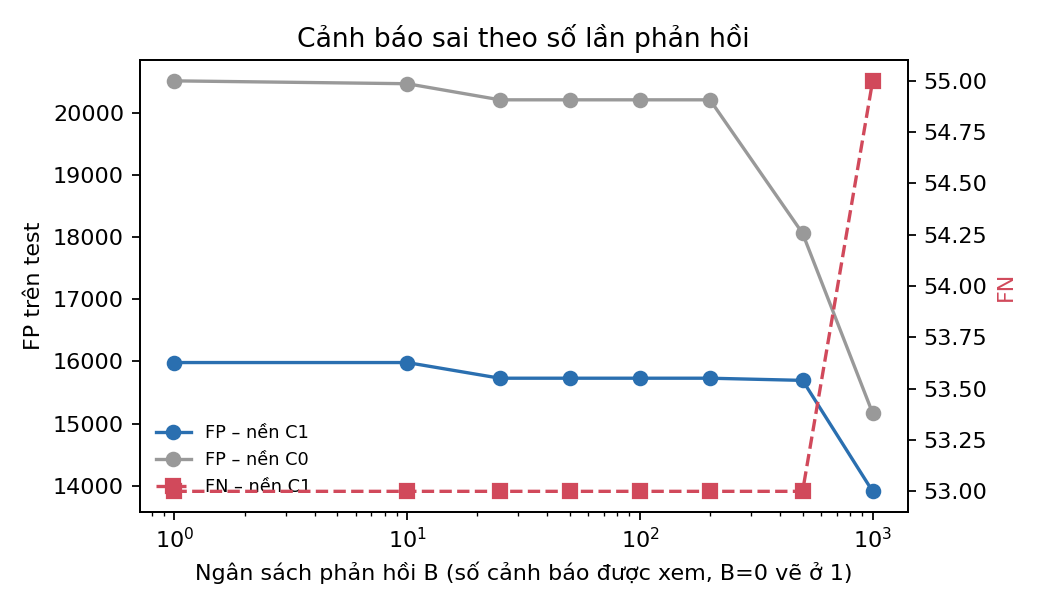

C6_theo_thoi_gian


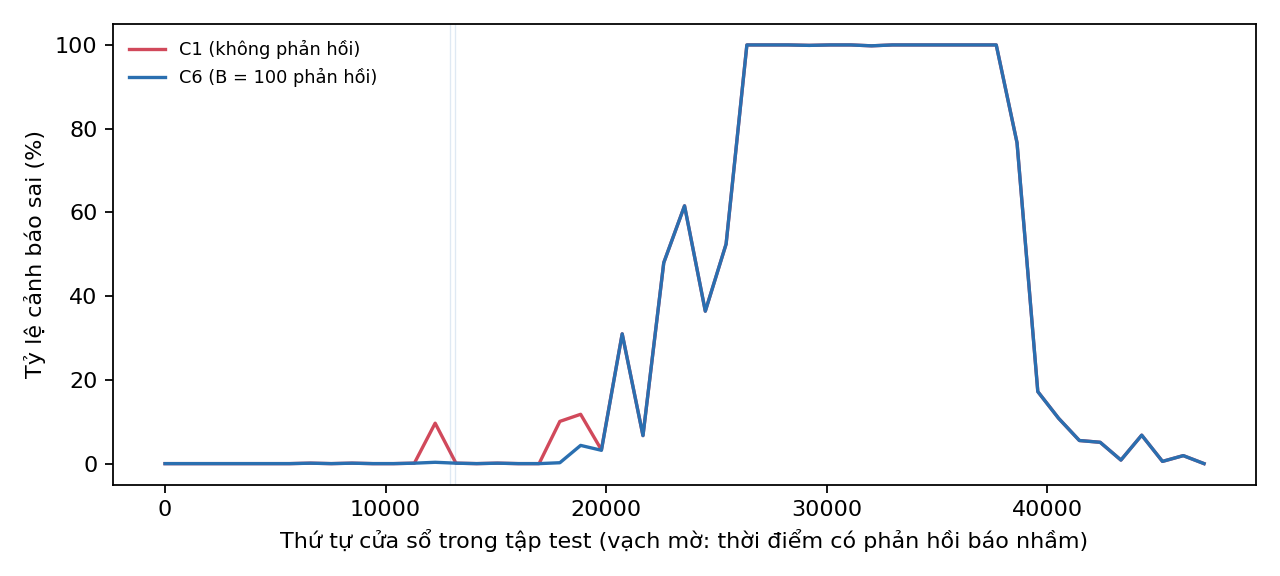

C5M_theo_thoi_gian


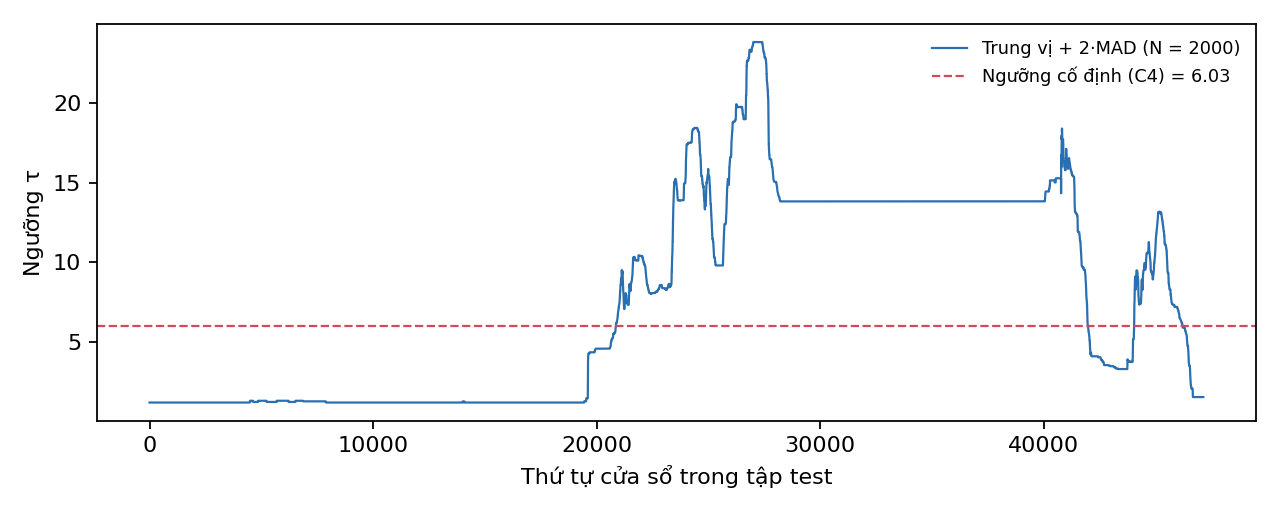

C5M_C1_theo_thoi_gian


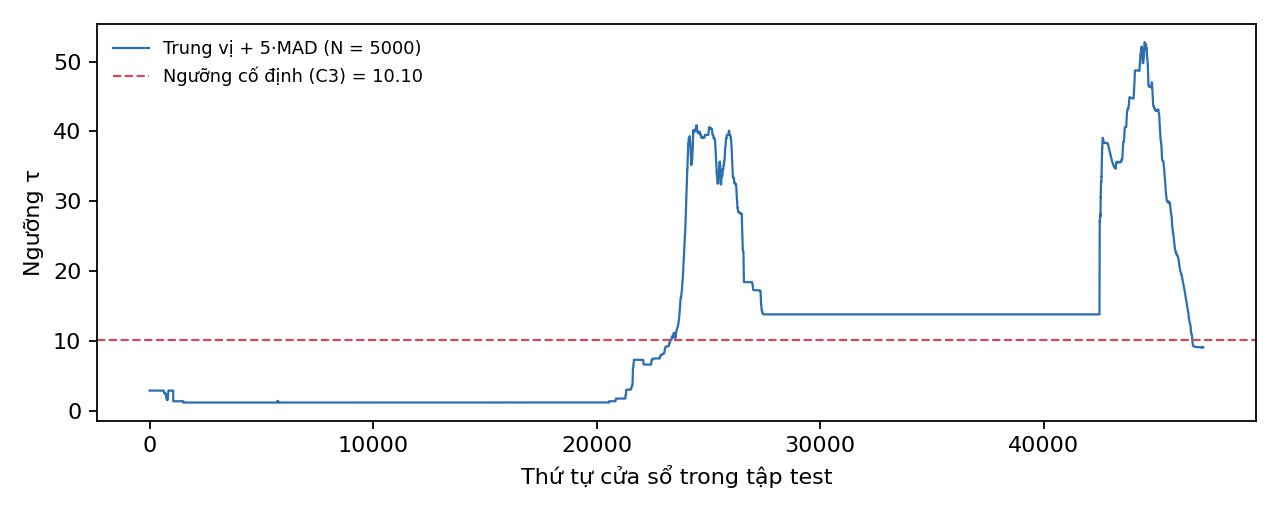

In [4]:
from IPython.display import Image, display
for f in ['C6_theo_ngan_sach', 'C6_theo_thoi_gian', 'C5M_theo_thoi_gian', 'C5M_C1_theo_thoi_gian']:
    print(f); display(Image(f'{R}/{f}.png'))